## Multiple Linear Regression

Now you know how to build a model with one X (feature variable) and Y (response variable). But what if you have three feature variables, or may be 10 or 100? Building a separate model for each of them, combining them, and then understanding them will be a very difficult and next to impossible task. By using multiple linear regression, you can build models between a response variable and many feature variables.

Let's see how to do that.

### Step_1 : Importing and Understanding Data

In [1]:
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

In [2]:
# Importing advertising.csv
advertising_multi = pd.read_csv('advertising.csv')
advertising_multi.shape

(200, 4)

In [3]:
advertising_multi.sample(5)

,TV,Radio,Newspaper,Sales
188,286.0,13.9,3.7,15.9
51,100.4,9.6,3.6,10.7
168,215.4,23.6,57.6,17.1
39,228.0,37.7,32.0,21.5
140,73.4,17.0,12.9,10.9


In [4]:
# Looking at the first five rows
advertising_multi.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [5]:
# Looking at the last five rows
advertising_multi.tail()

,TV,Radio,Newspaper,Sales
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5
199,232.1,8.6,8.7,13.4


In [6]:
advertising_multi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [7]:
advertising_multi.corr()

,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.782224
Radio,0.054809,1.000000,0.354104,0.576223
Newspaper,0.056648,0.354104,1.000000,0.228299
Sales,0.782224,0.576223,0.228299,1.000000


In [8]:
advertising_multi.corr(method="spearman")

,TV,Radio,Newspaper,Sales
TV,1.000000,0.056123,0.050840,0.800614
Radio,0.056123,1.000000,0.316979,0.554304
Newspaper,0.050840,0.316979,1.000000,0.194922
Sales,0.800614,0.554304,0.194922,1.000000


<Axes: >

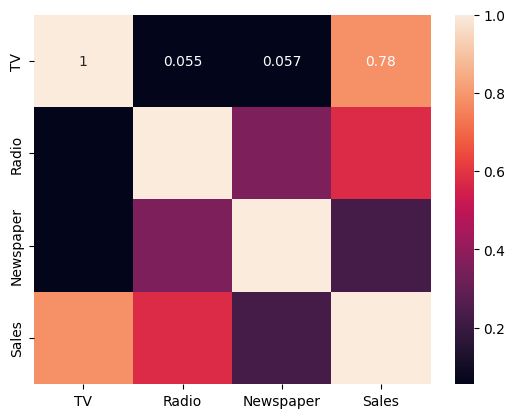

In [9]:
import seaborn as sns

sns.heatmap(advertising_multi.corr(),annot=True)

In [10]:
# What type of values are stored in the columns?
advertising_multi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [11]:
# Let's look at some statistical information about our dataframe.
advertising_multi.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


### Step_2: Visualising Data

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

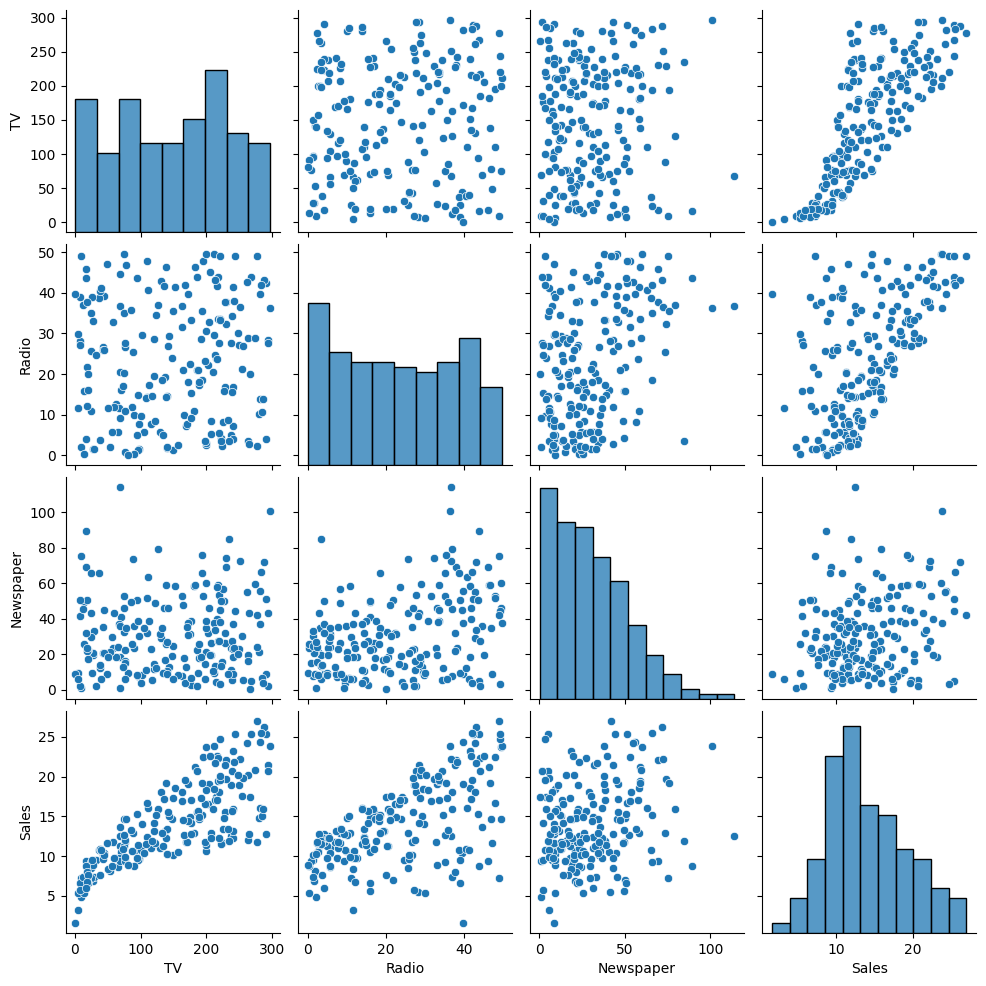

In [13]:
# Let's plot a pair plot of all variables in our dataframe
sns.pairplot(advertising_multi)

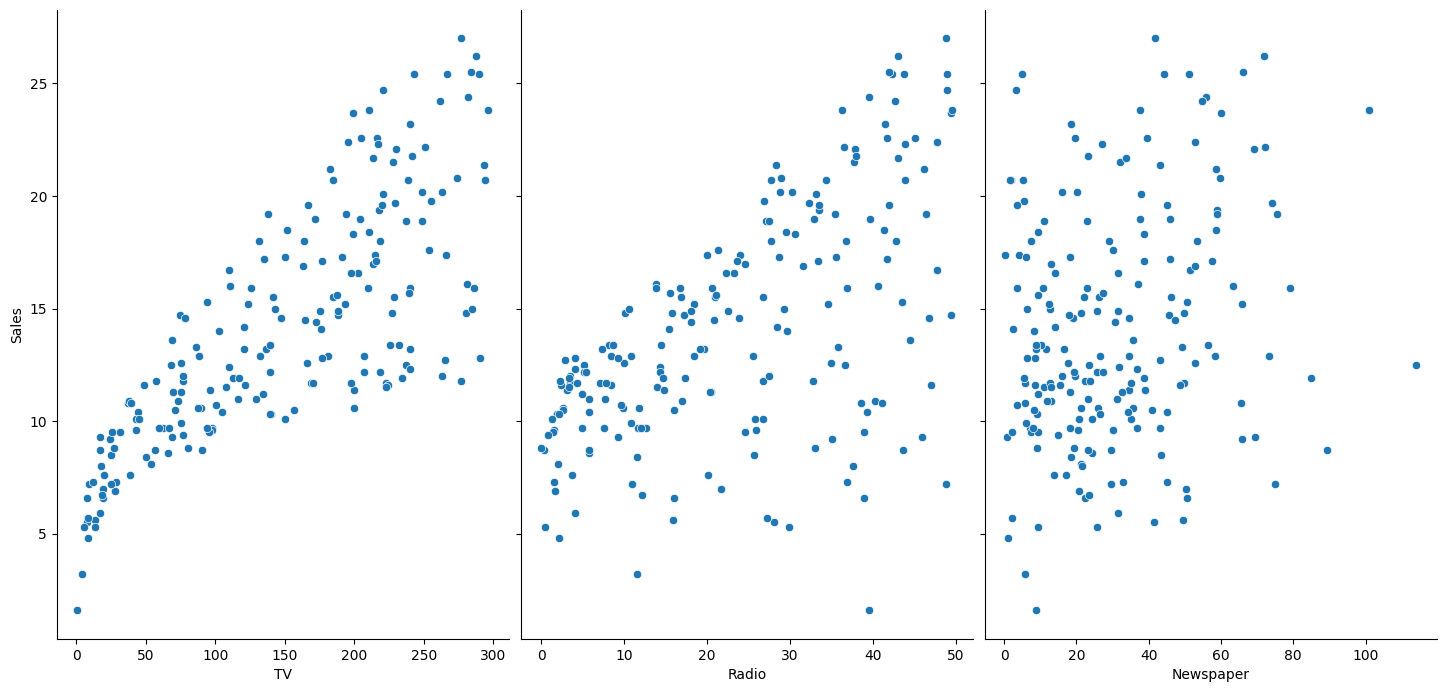

In [14]:
# Visualise the relationship between the features and the response using scatterplots
sns.pairplot(advertising_multi, x_vars=['TV','Radio','Newspaper'], y_vars='Sales',size=7, aspect=0.7, kind='scatter')

### Step_3: Splitting the Data for Training and Testing

In [15]:
# Putting feature variable to X
X = advertising_multi[['TV','Radio','Newspaper']]
# Putting response variable to y
y = advertising_multi['Sales']

In [16]:
#random_state is the seed used by the random number generator. It can be any integer.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7 , random_state=100)

In [17]:
y_train

74     17.0
3      18.5
185    22.6
26     15.0
90     11.2
       ... 
87     16.0
103    14.7
67     13.4
24      9.7
8       4.8
Name: Sales, Length: 140, dtype: float64

In [18]:
X_train[:5]

,TV,Radio,Newspaper
74,213.4,24.6,13.1
3,151.5,41.3,58.5
185,205.0,45.1,19.6
26,142.9,29.3,12.6
90,134.3,4.9,9.3


In [19]:
X_train.shape

(140, 3)

### Step_4 : Performing Linear Regression

In [20]:
from sklearn.linear_model import LinearRegression

In [21]:
# Representing LinearRegression as lr(Creating LinearRegression Object)
lm = LinearRegression()

In [45]:
# fit the model to the training data
lm.fit(X_train,y_train)

LinearRegression()

### Step_5 : Model Parameters

In [23]:
# print the intercept
print(lm.intercept_)
print(lm.coef_)

2.652789668879498
[0.0454256  0.18975773 0.00460308]


In [24]:
X_test.columns

Index(['TV', 'Radio', 'Newspaper'], dtype='object')

In [25]:
# Let's see the coefficient
coeff_df = pd.DataFrame(lm.coef_,X_test.columns,columns=['Coefficient'])
coeff_df

,Coefficient
TV,0.045426
Radio,0.189758
Newspaper,0.004603


**From the above result we may infern that if TV(X) advertising increses by 1 unit it will affect sales by 0.045 units.**

### Step_6 : Predictions

In [ ]:
# Making predictions using the model
y_pred = lm.predict(X_test)

### Step_7: Calculating Error Terms

In [27]:
from sklearn.metrics import mean_squared_error, r2_score
mse = mean_squared_error(y_test, y_pred)
r_squared = r2_score(y_test, y_pred)

In [28]:
print('Mean_Squared_Error :' ,mse)
print('r_square_value :',r_squared)

Mean_Squared_Error : 1.8506819941636963
r_square_value : 0.9058622107532246


In [29]:
#below value for all 3 features
r_squared*100

90.58622107532246

In [30]:
X_test.shape

(60, 3)

In [31]:
#below value for all 3 features

#adjusted rsquare:

n=X_test.shape[0]
p=X_test.shape[1]

adj_r2=1-(1-r_squared)*(n-1)/(n-p-1)
adj_r2*100

90.08191149007187

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

<Axes: >

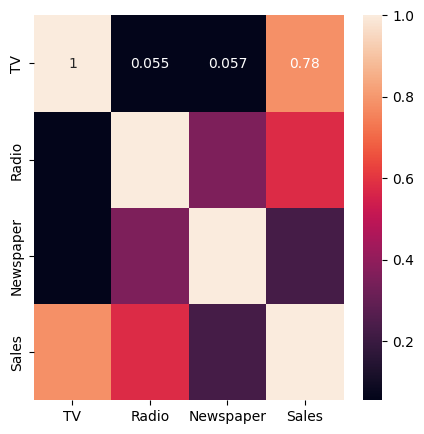

In [33]:
plt.figure(figsize = (5,5))
sns.heatmap(advertising_multi.corr(),annot = True)

### Step_8 : Implementing the results and running the model again

From the data above, you can conclude that Newspaper is insignificant.

In [34]:
# Removing Newspaper from our dataset
X_train_new = X_train[['TV','Radio']]
X_test_new = X_test[['TV','Radio']]

In [35]:
# Model building
lm.fit(X_train_new,y_train)

LinearRegression()

In [36]:
# Making predictions(2 features)
y_pred_new = lm.predict(X_test_new)

### Visualizing perf/error of old model(of 3 features) 
### Actual vs Predicted


Text(0, 0.5, 'Sales')

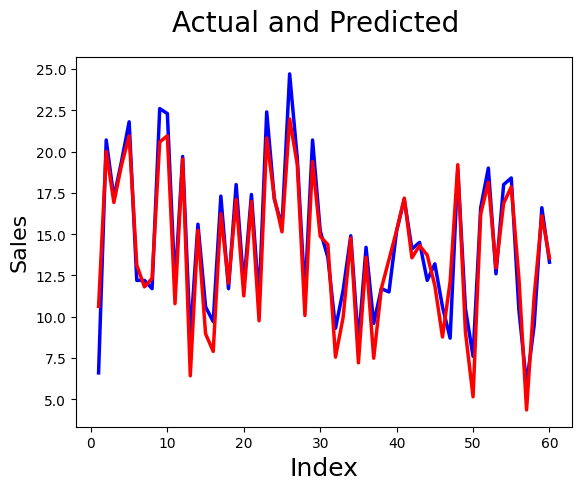

In [37]:
#Actual vs Predicted having all 3 features
c = [i for i in range(1,61,1)]
fig = plt.figure()
plt.plot(c,y_test, color="blue", linewidth=2.5, linestyle="-")
plt.plot(c,y_pred, color="red",  linewidth=2.5, linestyle="-")
fig.suptitle('Actual and Predicted', fontsize=20)              # Plot heading 
plt.xlabel('Index', fontsize=18)                               # X-label
plt.ylabel('Sales', fontsize=16)                               # Y-label

Text(0, 0.5, 'ytest-ypred')

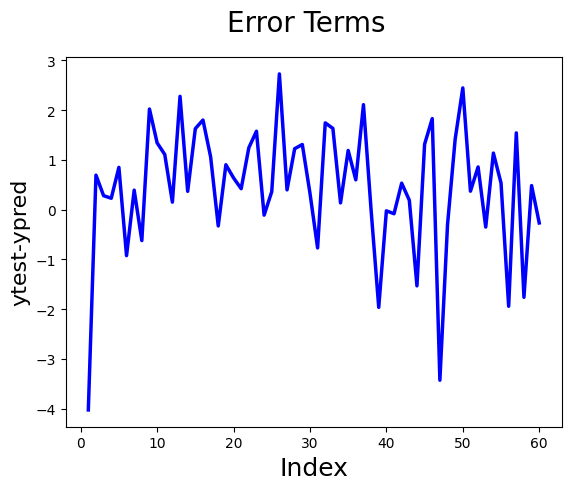

In [38]:
# Error terms for all 3 features
c = [i for i in range(1,61,1)]
fig = plt.figure()

plt.plot(c,y_test-y_pred, color="blue", linewidth=2.5, linestyle="-")

fig.suptitle('Error Terms', fontsize=20)              # Plot heading 
plt.xlabel('Index', fontsize=18)                      # X-label
plt.ylabel('ytest-ypred', fontsize=16)                # Y-label

## Performance of model for 2 features


In [39]:
# Performance of model for 2 features

from sklearn.metrics import mean_squared_error, r2_score
mse = mean_squared_error(y_test, y_pred_new)
r_squared = r2_score(y_test, y_pred_new)

In [40]:
#New Metrics with 2 features

print('Mean_Squared_Error :' ,mse)
print('r_square_value :',r_squared)

#old with 3 features
# Mean_Squared_Error : 1.850681994163694
# r_square_value : 0.9058622107532247

Mean_Squared_Error : 1.7847400520902805
r_square_value : 0.909216449171822


In [41]:
sales_predicted = lm.predict([[44.5,43.45]])
sales_predicted

array([13.1088723])

In [42]:
X_train_new.shape

(140, 2)

In [43]:
y_train.shape

(140,)

### Simple Linear Regression: Newspaper(X) and Sales(y)

In [44]:
import pandas as pd
import numpy as np
# Importing dataset
advertising_multi = pd.read_csv('advertising.csv')

x_news = advertising_multi['Newspaper']

y_news = advertising_multi['Sales']

# Data Split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x_news, y_news, 
                                                    train_size=0.7 , 
                                                    random_state=110)

# Required only in the case of simple linear regression
# X_train = X_train[:,np.newaxis]
# X_test = X_test[:,np.newaxis]

X_train = np.reshape(X_train,(-1,1))
X_test = np.reshape(X_test,(-1,1))


# Linear regression from sklearn
from sklearn.linear_model import LinearRegression
lm = LinearRegression()

# Fitting the model
lm.fit(X_train,y_train)

# Making predictions
y_pred = lm.predict(X_test)

# Importing mean square error and r square from sklearn library.
from sklearn.metrics import mean_squared_error, r2_score

# Computing mean square error and R square value
mse = mean_squared_error(y_test, y_pred)
r_squared = r2_score(y_test, y_pred)

# Printing mean square error and R square value
print('Mean_Squared_Error :' ,mse)
print('r_square_value :',r_squared)

Mean_Squared_Error : 23.84732008485191
r_square_value : 0.08182413570736657
